<a href="https://colab.research.google.com/github/MarioFernando-MF/ProyectoP1-GrupoC/blob/main/ProyectoP1_ELNO4_2_GrupoC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto Parcial I: Predicción del rendimiento académico
**Materia:** Aprendizaje Automático  
**Paralelo:** CDIA - ELNO - 4/2, CI 2026-2027  
**Grupo:** C  
**Fecha:** 25 de noviembre de 2026  

**Integrantes**
- Alcívar Zambrano Derian Esneyder
- Carvajal Guerra Britanie Brigithe
- Cassagne Morales Ricardo Paul
- Correa Tandazo Richard Samuel
- Martínez Ibáñez Mario Fernando
- Sancán Pérez Andre Alejandro

# Parte 1. Análisis exploratorio de datos (EDA)


##1.- Carga el dataset y describe su estructura: filas, columnas, tipos de variables y estadísticas descriptivas.

Usamos el archivo student-mat.csv, que corresponde al curso de Matemáticas.

In [1]:
# Librerías de datos y gráficos
import numpy as np                 # para cálculos numéricos
import pandas as pd                # para tablas de datos
import matplotlib.pyplot as plt    # para gráficos
import seaborn as sns              # para gráficos estadísticos

# Semilla del grupo: somos 6 integrantes
SEMILLA = 6

En esta parte leemos el archivo desde nuestro repositorio guardado en GitHub.

Aquí ejecutamos el código para revisar cuántas filas y columnas tiene la data del archivo cargado y mostrar las primeras cinco filas.

In [2]:
# Leemos el archivo desde nuestro repositorio de GitHub
url = "https://raw.githubusercontent.com/mariomartinez1313-ship-it/ProyectoP1-GrupoC/main/student-mat.csv"
df = pd.read_csv(url)

print("Filas y columnas:", df.shape)
df.head()  # muestra las 5 primeras filas

Filas y columnas: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


En esta parte revisamos el nombre y el tipo de dato de cada columna.

In [3]:
# Tipo de dato de cada columna: int es número y str u object es texto
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    object
 20  higher    

En este dataset se puede visualizar que tiene listado 395 estudiantes y 33 variables. Hay 16 variables numéricas y 17 de texto. Todas las columnas tienen datos, por lo que nos asegura que no se ven valores faltantes y estarían completos.


En la siguiente parte se calcula cantidad, promedio, desviación, mínimo, cuartiles y máximo de las variables numéricas.

In [4]:
# Estadísticas de las variables numéricas
# Consideramos usar 2 decimales
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,395.0,16.70,1.28,15.0,16.0,17.0,18.0,22.0
Medu,395.0,2.75,1.09,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,2.52,1.09,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.45,0.70,1.0,1.0,1.0,2.0,4.0
studytime,395.0,2.04,0.84,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.33,0.74,0.0,0.0,0.0,0.0,3.0
famrel,395.0,3.94,0.90,1.0,4.0,4.0,5.0,5.0
freetime,395.0,3.24,1.00,1.0,3.0,3.0,4.0,5.0
goout,395.0,3.11,1.11,1.0,2.0,3.0,4.0,5.0
Dalc,395.0,1.48,0.89,1.0,1.0,1.0,2.0,5.0


Al desplegar la tabla podemos ver que la nota final G3 tiene un promedio de 10.42 sobre 20 y una mediana de 11. La nota más baja es 0 y la más alta es 20.
Sin embargo, nos llama la atención la variable absences: el promedio es de 5.71 ausencias, pero existe un máximo de 75.

Ahora revisamos las variables de texto para conocer cuántas categorías tienen y cuál se repite más.

In [5]:
# Resumen de las variables de texto
df.describe(exclude="number").T

,count,unique,top,freq
school,395,2,GP,349
sex,395,2,F,208
address,395,2,U,307
famsize,395,2,GT3,281
Pstatus,395,2,T,354
Mjob,395,5,other,141
Fjob,395,5,other,217
reason,395,4,course,145
guardian,395,3,mother,273
schoolsup,395,2,no,344


En las variables de texto podemos observar su estadística, siendo lo más relevante que la mayoría pertenece al TOP GP de escuelas el son 349. Además que la mayor parte de estudiantes son mujeres sinedo 208 de sexo F.

## 2.- Grafica la distribución de G3 y la de al menos tres variables que consideres relevantes.

En esta parte realizamos el código para graficar la nota final, las reprobaciones previas, el tiempo de estudio y las ausencias.

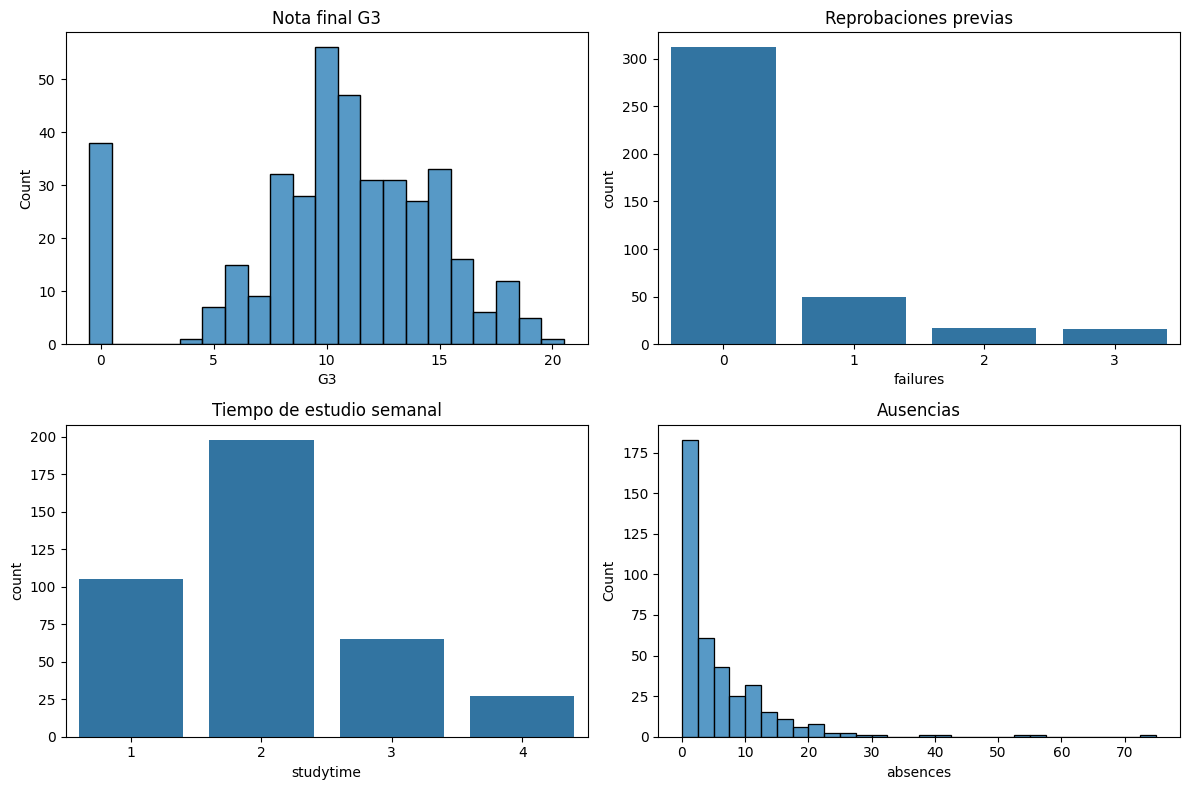

In [6]:
# Generación de 4 gráficos
fig, ax = plt.subplots(2, 2, figsize=(12, 8))

sns.histplot(df["G3"], bins=np.arange(-0.5, 21.5), ax=ax[0, 0])
ax[0, 0].set_title("Nota final G3")

sns.countplot(x="failures", data=df, ax=ax[0, 1])
ax[0, 1].set_title("Reprobaciones previas")

sns.countplot(x="studytime", data=df, ax=ax[1, 0])
ax[1, 0].set_title("Tiempo de estudio semanal")

sns.histplot(df["absences"], bins=30, ax=ax[1, 1])
ax[1, 1].set_title("Ausencias")

plt.tight_layout()  # evita que los gráficos se encimen
plt.show()

En el primer gráfico se puede ver que la mayoría de las notas finales G3 está entre 8 y 15.
El gráfico de reprobaciones previas presenta a la mayor parte de los estudiantes en 0 y muy pocos tienen 2 o 3.
El gráfico de tiempo de estudio refleja que el más común es el nivel 2, que equivale a entre 2 y 5 horas por semana, mientras que pocos estudian más de 10 horas.
El gráfico de ausencias muestra pocas ausencias ya que sus barras están concetradas en menor a 10 pero si hay algunos casos con valores muy altos que llegan hasta 75.

##3.- Calcula la matriz de correlación de las variables numéricas e identifica las más relacionadas con G3.

La correlación va de -1 a 1. Mientras más lejos de 0, más fuerte es la relación.

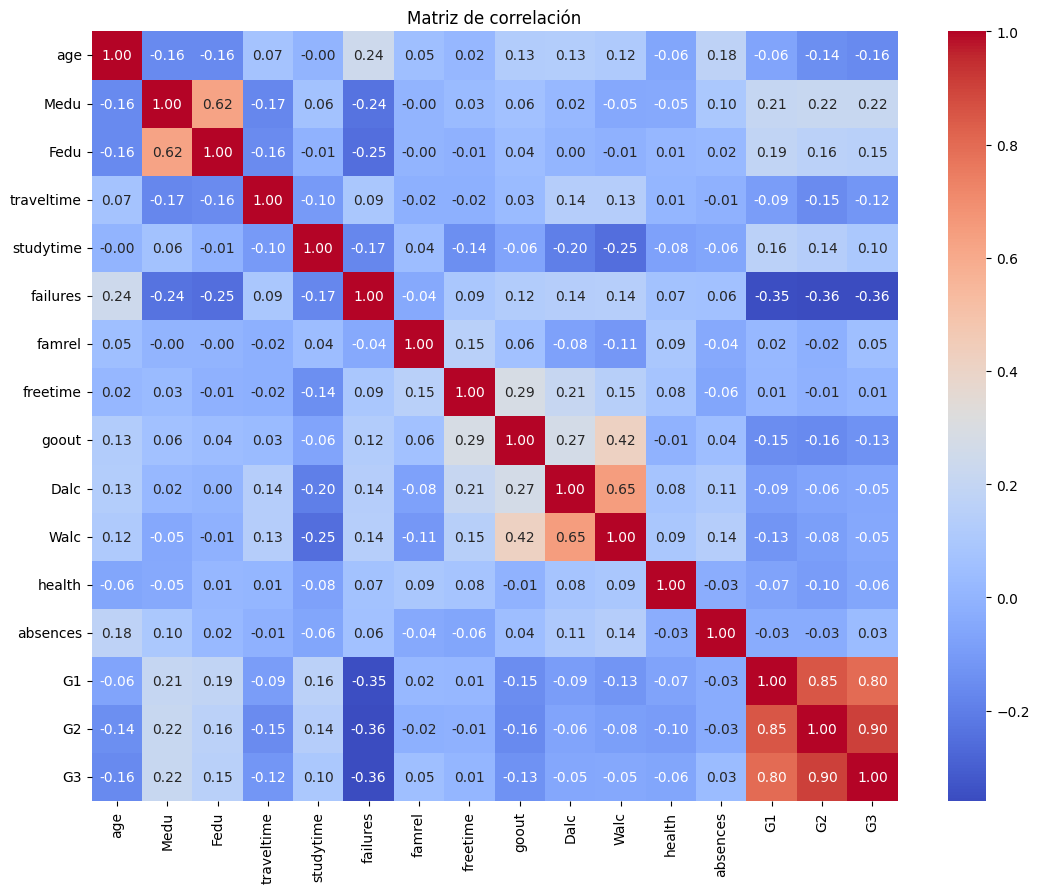

,G3
G3,1.00
G2,0.90
G1,0.80
Medu,0.22
Fedu,0.15
studytime,0.10
famrel,0.05
absences,0.03
freetime,0.01
Walc,-0.05


In [7]:
corr = df.corr(numeric_only=True)  # solo variables numéricas
plt.figure(figsize=(13, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Matriz de correlación")
plt.show()

corr["G3"].sort_values(ascending=False).round(2)  # ordena la relación con G3

En la matriz vemos que hay variables que están más relacionadas con la nota final G3 y son G2 con 0.90 y G1 con 0.80, lo que indica que los estudiantes han terminado con una buena nota final. También se muestran las reprobaciones previas con -0.36, una relación negativa que muestra que a más reprobaciones la nota final tiende a ser menor.

##4.- Escribe tres hallazgos con tus propias palabras. Por ejemplo: "Los estudiantes con reprobaciones previas tienen en promedio X puntos menos en la nota final".

Con el siguiente código vamos a revisar las reprobaciones, la educación de la madre y los estudiantes con nota 0.

In [8]:
# Nota promedio según las reprobaciones
print(df.groupby("failures")["G3"].mean().round(2))
print("Sin reprobaciones:", round(df[df["failures"] == 0]["G3"].mean(), 2))
print("Con reprobaciones:", round(df[df["failures"] > 0]["G3"].mean(), 2))

# Nota promedio y cantidad según la educación de la madre
print(df.groupby("Medu")["G3"].agg(["mean", "count"]).round(2))

# Estudiantes con nota 0
ceros = df[df["G3"] == 0]
print("Con nota 0:", len(ceros))
print("Máximo de ausencias:", ceros["absences"].max())

failures
0    11.25
1     8.12
2     6.24
3     5.69
Name: G3, dtype: float64
Sin reprobaciones: 11.25
Con reprobaciones: 7.27
       mean  count
Medu              
0     13.00      3
1      8.68     59
2      9.73    103
3     10.30     99
4     11.76    131
Con nota 0: 38
Máximo de ausencias: 0


Descripción de 3 hallazgos:

1.- La nota promedio de los estudiantes que no han reprobado es de 11.25 mientras que los que tienen reprobaciones previas tienen un promedio de 7.27, esto representa 3.98 puntos menos en la nota final.

2.- Mientras la educación de la madre es más alta, el estudiante saca mejor nota. Se observa que en el nivel 4 el promedio es de 11.76.

3.- Se presentan 38 estudiantes con nota 0 y ninguno de los estudiantes tienen ausencias (igual a 0),  Esto puede ser extraño ya que asistiendo a clases no han podido conseguir un puntaje mayor a 0.


# Parte 2. Preprocesamiento



## 1.- Verifica si existen valores faltantes y duplicados. Ojo con este punto. El dataset original no tiene faltantes: introduce un 5 % de valores faltantes al azar en absences y en studytime, e impútalos justificando la estrategia que elijas.

Primero revisamos si hy datos vacíos o repetidos para saber en qué estado estan antes de modificarlos.

In [9]:
print(df.isna().sum())  # datos vacíos por columna
print("Total de faltantes:", df.isna().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64
Total de faltantes: 0
Filas duplicadas: 0


La data del archivo que estamos analizando no ha generado valores faltantes ni filas duplicadas en este reporte, conociendo esto aplicaremos lo solicitado, crear un 5% de valores faltantes en absences y studytime.

In [10]:
datos = df.copy()  # copia para no modificar los datos originales

rng = np.random.default_rng(SEMILLA)   # sorteo repetible
cantidad = round(0.05 * len(datos))    # 5 % de 395 son 20 filas

for col in ["absences", "studytime"]:
    datos[col] = datos[col].astype(float)  # permite guardar vacíos
    filas = rng.choice(datos.index, size=cantidad, replace=False)
    datos.loc[filas, col] = np.nan         # deja el dato vacío

print(datos[["absences", "studytime"]].isna().sum())

absences     20
studytime    20
dtype: int64


Se crearon 20 valores faltantes en absences y 20 en studytime, que corresponden al 5% de los 395 estudiantes.

Las filas se eligieron al azar usando la semilla 6, porque somos seis integrantes en el grupo, así siempre se obtienen las mismas filas.


### IMPUTACIÓN
Para tomar una decisión sobre con qué valor rellenar los datos vacíos, vamos a ejecutar un código que nos permita obtener la media, la mediana y la moda para elegir con cuál trabajar.

In [11]:
print("Media de ausencias:", round(datos["absences"].mean(), 2))
print("Mediana de ausencias:", datos["absences"].median())
print("Moda de studytime:", datos["studytime"].mode()[0])

Media de ausencias: 5.81
Mediana de ausencias: 4.0
Moda de studytime: 2.0


En el caso de las ausencias vamos a usar la mediana que es 4, ya que hay pocos estudiantes que tienen muchas ausencias y eso hace que el promedio suba a 5.81. Para el tiempo de estudio vamos a usar la moda que es 2, porque es la respuesta que más se repite y sus valores van del 1 al 4.

### 2. Detecta valores atípicos en absences con la regla IQR y decide si los tratas o los conservas. Justifica tu decisión.



Para saber qué hacer con los valores que no son comunes, primero realizaremos un código que nos permita buscar los valores de ausencias que tienen mucha diferencia con la mayoría de valores.

Límite inferior: -12.0
Límite superior: 20.0
Cantidad de atípicos: 15
Máximo de ausencias: 75.0


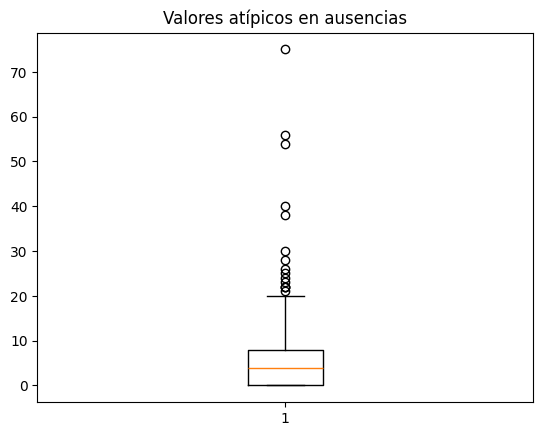

In [12]:
def limites_iqr(serie):
    q1 = serie.quantile(0.25)   # percentil 25
    q3 = serie.quantile(0.75)   # percentil 75
    iqr = q3 - q1               # rango intercuartílico
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

inf, sup = limites_iqr(datos["absences"])
atipicos = datos[(datos["absences"] < inf) | (datos["absences"] > sup)]

print("Límite inferior:", inf)
print("Límite superior:", sup)
print("Cantidad de atípicos:", len(atipicos))
print("Máximo de ausencias:", datos["absences"].max())

plt.boxplot(datos["absences"].dropna())  # sin contar los vacíos
plt.title("Valores atípicos en ausencias")
plt.show()

Generó un resultado de valores atípicos que serían 15 estudiantes con más de 20 ausencias (límite superior) y el que más tiene llega a 75 (máximo de ausencias). Podemos conservar estos datos ya que un estudiante si podría tener esa cantidad de faltas por ausencia que no ha reportado o justificado. Además pueden ser estudiantes con algún problema puntual que también es importante identificar, pero se debe considerar que estos valores altos podrían influir en el resultado.

### 3. Codifica las variables categóricas con One-Hot Encoding y escala las numéricas, según corresponda y justificar la necesidad de hacerlo.



En este paso vamos a separar las columnas de texto y las que son numéricas para saber cómo podemos organizar cada grupo.

In [13]:
# Las columnas de texto se codifican
texto = datos.select_dtypes(exclude="number").columns.tolist()

# Las columnas numéricas se escalan
# G3 lo excluímos porque es la nota que vamos a predecir
# studytime va aparte porque se rellena con el valor obtenido de la moda

numeros = datos.select_dtypes("number").columns.drop(["G3", "studytime"]).tolist()

print("Texto:", len(texto), texto)
print("Numéricas:", len(numeros), numeros)

Texto: 17 ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']
Numéricas: 14 ['age', 'Medu', 'Fedu', 'traveltime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']


Se observa que tenemos 17 columnas de texto, las cuales vamos a convertir en columnas de 0 y 1 con One-Hot Encoding, debido a que los modelos solo trabajan con números.

También se observa que tenemos 14 columnas numéricas que junto con el tiempo de estudio vamos a escalar para que queden en una escala parecida, consideramos que de esta forma en los modelos que lo requieren ninguna pese más solo por tener valores grandes.

##4. Integra el preprocesamiento en un Pipeline con ColumnTransformer.

En este paso vamos a generar el código que nos permita unir el relleno de datos vacíos, la codificación y el escalado en un solo proceso.

In [14]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

def crear_preprocesador(X):
    # Aquí separamos las columnas de los datos recibidos
    texto = X.select_dtypes(exclude="number").columns.tolist()
    numeros = X.select_dtypes("number").columns.drop("studytime").tolist()

    # Para los números: rellenamos con la mediana y escalamos
    pasos_numeros = Pipeline([("imputar", SimpleImputer(strategy="median")),
                              ("escalar", StandardScaler())])
    # Para el tiempo de estudio: rellenamos con la moda y escalamos
    pasos_estudio = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                              ("escalar", StandardScaler())])
    # A los textos: convertimos en columnas de 0 y 1
    codificar = OneHotEncoder(drop="first", handle_unknown="ignore")

    return ColumnTransformer([("numeros", pasos_numeros, numeros),
                              ("estudio", pasos_estudio, ["studytime"]),
                              ("texto", codificar, texto)],
                             verbose_feature_names_out=False)

crear_preprocesador(datos.drop(columns="G3"))  # Nos va muestrar el esquema

ColumnTransformer(transformers=[('numeros',
                                 Pipeline(steps=[('imputar',
                                                  SimpleImputer(strategy='median')),
                                                 ('escalar',
                                                  StandardScaler())]),
                                 ['age', 'Medu', 'Fedu', 'traveltime',
                                  'failures', 'famrel', 'freetime', 'goout',
                                  'Dalc', 'Walc', 'health', 'absences', 'G1',
                                  'G2']),
                                ('estudio',
                                 Pipeline(steps=[('imputar',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('escalar',
                                                  StandardScaler())]),
                                 ['studytime']),
                                ('texto',
                                 OneHotEncoder(drop='first',
                                               handle_unknown='ignore'),
                                 ['school', 'sex', 'address', 'famsize',
                                  'Pstatus', 'Mjob', 'Fjob', 'reason',
                                  'guardian', 'schoolsup', 'famsup', 'paid',
                                  'activities', 'nursery', 'higher', 'internet',
                                  'romantic'])],
                  verbose_feature_names_out=False)

Se observa un esquema con tres grupos que son números, estudio y texto. En las columnas numéricas se rellenan los vacíos con la mediana y luego se escalan, en el tiempo de estudio se rellenan con la moda y se escalan, y las columnas de texto se convierten en columnas de 0 y 1.

## 5.- Divide los datos en entrenamiento (80 %) y prueba (20 %) la semilla debe ser un número que el grupo justifique (no el 42).

Para este punto usamos la semilla 6 que definimos al crear el 5% de valores faltantes en absences y studytime. Como no se puede usar 42, decidimos usar 6 porque es el número de integrantes del grupo. Este número no tiene nada que ver con algún valor de los datos, solo es un número que fijamos para que en la división siempre queden los mismos estudiantes en entrenamiento y en prueba.

In [15]:
from sklearn.model_selection import train_test_split

X = datos.drop(columns="G3")   # variables para predecir
y = datos["G3"]                # nota que vamos a predecir

# 80 % para entrenamiento y 20 % para prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEMILLA)

prep = crear_preprocesador(X_train)
X_train_prep = prep.fit_transform(X_train)  # aprende y transforma con entrenamiento
X_test_prep = prep.transform(X_test)        # solo transforma la prueba

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)
print("Entrenamiento transformado:", X_train_prep.shape)
print("Prueba transformada:", X_test_prep.shape)
print("Vacíos en entrenamiento:", np.isnan(X_train_prep).sum())
print("Vacíos en prueba:", np.isnan(X_test_prep).sum())

Entrenamiento: (316, 32)
Prueba: (79, 32)
Entrenamiento transformado: (316, 41)
Prueba transformada: (79, 41)
Vacíos en entrenamiento: 0
Vacíos en prueba: 0


Se observa que quedaron 316 estudiantes para entrenamiento y 79 para prueba.

Después de aplicar el Pipeline las 32 columnas pasaron a ser 41, porque las columnas de texto se convirtieron en columnas de 0 y 1, y ya no quedan datos vacíos.

Los valores para rellenar y escalar se calculan solo con los datos de entrenamiento, para que los datos de prueba no influyan en el resultado.

#Parte 3. Regresión lineal múltiple: predecir G3

### 3.1. Entrena dos modelos de regresión lineal.
###  -Modelo A: usando todas las variables, incluidas G1 y G2.
###  -Modelo B: usando todas las variables excepto G1 y G2.



En este paso vamos a entrenar el modelo A con todas las variables y el modelo B sin las notas G1 y G2.

In [16]:
from sklearn.linear_model import LinearRegression

# Modelo A: usa todas las variables
modelo_a = Pipeline([("prep", crear_preprocesador(X_train)),
                     ("reg", LinearRegression())])
modelo_a.fit(X_train, y_train)        # aprende
pred_a = modelo_a.predict(X_test)     # predice

# Modelo B: quitamos G1 y G2
Xb_train = X_train.drop(columns=["G1", "G2"])
Xb_test = X_test.drop(columns=["G1", "G2"])
modelo_b = Pipeline([("prep", crear_preprocesador(Xb_train)),
                     ("reg", LinearRegression())])
modelo_b.fit(Xb_train, y_train)
pred_b = modelo_b.predict(Xb_test)

print("Variables del modelo A:", X_train.shape[1])
print("Variables del modelo B:", Xb_train.shape[1])
print("Primeras notas reales:", y_test.head().tolist())
print("Predichas por A:", pred_a[:5].round(1))
print("Predichas por B:", pred_b[:5].round(1))

Variables del modelo A: 32
Variables del modelo B: 30
Primeras notas reales: [13, 0, 11, 8, 16]
Predichas por A: [12.4  0.  10.6  6.3 14.9]
Predichas por B: [11.5 10.1 12.1 12.7 10.3]


Se observa que en estos cinco casos el modelo A se acerca más a las notas reales, por ejemplo cuando la nota real es 13 predice 12.4 y cuando es 16 predice 14.9. En cambio el modelo B se aleja más, incluso al estudiante con nota 0 le predice 10.1 lo cual es irreal, bien alejado de la realidad.
Con esta muestra nuestro siguiente paso sería evaluar el error con todos los datos de prueba.


### 3.2. Para cada modelo calcula MSE, RMSE y R² en el conjunto de prueba, no olvidar interpretación de los resultados.


En este paso vamos a medir el error de los dos modelos con todos los datos de prueba.

In [17]:
from sklearn.metrics import mean_squared_error, r2_score

def metricas(nombre, pred):
    mse = mean_squared_error(y_test, pred)  # error cuadrático medio
    rmse = np.sqrt(mse)                     # error en puntos de nota
    r2 = r2_score(y_test, pred)             # qué tanto explica el modelo
    print(nombre, "MSE:", round(mse, 3), "RMSE:", round(rmse, 3), "R2:", round(r2, 3))

metricas("Modelo A", pred_a)
metricas("Modelo B", pred_b)

Modelo A MSE: 4.865 RMSE: 2.206 R2: 0.784
Modelo B MSE: 17.961 RMSE: 4.238 R2: 0.201


Se observa que el modelo A se equivoca menos, ya que su error es de unos 2.2 puntos en la nota mientras que el del modelo B es de 4.2 puntos. El MSE también es menor en el modelo A con 4.865 frente a 17.961. En el R2 el modelo A tiene 0.784, es decir que logra explicar cerca del 78% de los cambios en las notas, en cambio el modelo B solo explica un 20%. Esto nos muestra que sin las notas G1 y G2 es mucho más difícil predecir la nota final.

### 3.3. Para el Modelo B, calcula a mano con NumPy al menos una de las métricas y compárala con scikit-learn.


En este paso vamos a calcular las métricas del modelo B usando las fórmulas para comprobar que salen iguales.

In [18]:
real = y_test.to_numpy()
errores = real - pred_b                      # real menos predicho

mse_manual = np.mean(errores ** 2)           # promedio de errores al cuadrado
rmse_manual = np.sqrt(mse_manual)            # raíz del MSE
suma_errores = np.sum(errores ** 2)
suma_total = np.sum((real - real.mean()) ** 2)
r2_manual = 1 - suma_errores / suma_total

print("MSE  NumPy:", round(mse_manual, 3), " sklearn:", round(mean_squared_error(y_test, pred_b), 3))
print("RMSE NumPy:", round(rmse_manual, 3), " sklearn:", round(np.sqrt(mean_squared_error(y_test, pred_b)), 3))
print("R2   NumPy:", round(r2_manual, 3), " sklearn:", round(r2_score(y_test, pred_b), 3))

MSE  NumPy: 17.961  sklearn: 17.961
RMSE NumPy: 4.238  sklearn: 4.238
R2   NumPy: 0.201  sklearn: 0.201


Se observa que los resultados calculados a mano con NumPy son iguales a los de scikit-learn. El MSE es 17.961, el RMSE es 4.238 y el R2 es 0.201, con esto comprobamos que las métricas están bien calculadas.

### 3.4. Para el Modelo B, revisa los 5 supuestos de la regresión lineal (linealidad, independencia, homocedasticidad, normalidad de residuos y no multicolinealidad), con gráficos y cálculos.
Primero obtenemos los residuos del modelo B con los datos de entrenamiento. El residuo es la nota real menos la nota predicha.

In [19]:
import statsmodels.api as sm

nombres = modelo_b["prep"].get_feature_names_out()   # nombres de las columnas
Z = pd.DataFrame(modelo_b["prep"].transform(Xb_train), columns=nombres, index=Xb_train.index)
Z = sm.add_constant(Z)                 # agrega el intercepto
ols = sm.OLS(y_train, Z).fit()         # mismo modelo en statsmodels
ajustados = ols.fittedvalues           # notas predichas
residuos = ols.resid                   # real menos predicho

print("Cantidad de residuos:", len(residuos))

Cantidad de residuos: 316


Supuesto 1: Linealidad
Revisamos que los residuos no formen una curva.

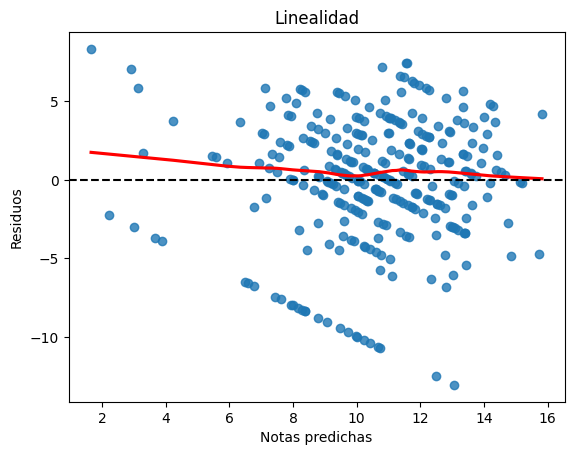

In [20]:
from statsmodels.stats.diagnostic import linear_reset

sns.regplot(x=ajustados, y=residuos, lowess=True, line_kws={"color": "red"})
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Notas predichas")
plt.ylabel("Residuos")
plt.title("Linealidad")
plt.show()

La prueba RESET da un valor p de 0.063 que es mayor a 0.05, por lo que no encontramos pruebas de que falte una relación curva, aunque el valor está cerca del límite. En el gráfico también se debe observar si la línea roja se mantiene cerca de 0.

### Pregunta crítica: el Modelo A tendrá un R² mucho más alto. ¿Sirve en la práctica un modelo que necesita la nota del segundo período para predecir la nota final si la institución quiere actuar a tiempo?

Como nota, es importante mencionar que el modelo A tiene un R² de 0.784 y el modelo B solo de 0.201, creemos que en la práctica el modelo A no ayuda mucho si queremos actuar a tiempo, ya que necesita la nota del segundo período y para ese momento queda poco tiempo para apoyar al estudiante.

Por otro lado la fuga de datos pasa cuando el modelo usa información que todavía no tendríamos en el momento de predecir, y eso hace que los resultados se vean mejor de lo que serían en la realidad. Por ejemplo, si queremos predecir al inicio del año, no podemos usar G1 y G2.

En base a lo menciona, recomendamos el modelo B porque se puede usar antes de tener las notas. Sabemos que se equivoca en unos 4.2 puntos y que solo explica el 20% de los cambios en las notas, por eso lo usaríamos como una primera alerta y no para decidir sobre un estudiante sin revisar su caso.

## Parte 4. Regresión logística: predecir si aprueba
### 1. Crea la variable objetivo aprueba: 1 si G3 ≥ 10 y 0 en caso contrario.
En este paso vamos a crear una columna que indique si el estudiante aprueba o no.

In [21]:
datos_log = datos.copy()
datos_log["aprueba"] = (datos_log["G3"] >= 10).astype(int)  # 1 aprueba, 0 no aprueba

print(datos_log[["G3", "aprueba"]].head())
print(datos_log["aprueba"].value_counts())

   G3  aprueba
0   6        0
1   6        0
2  10        1
3  15        1
4  10        1
aprueba
1    265
0    130
Name: count, dtype: int64


Se observa que 265 estudiantes aprueban y 130 no aprueban, es decir que cerca del 67% tiene una nota de 10 o más. Con esta nueva columna vamos a entrenar el modelo.

### 2. Entrena una regresión logística sin G1, G2 ni G3.
En este paso vamos a entrenar el modelo que estima la probabilidad de que un estudiante apruebe, sin usar ninguna de las notas.

In [22]:
from sklearn.linear_model import LogisticRegression

X_log = datos_log.drop(columns=["G1", "G2", "G3", "aprueba"])
y_log = datos_log["aprueba"]

# 80 % y 20 %, manteniendo la proporción de aprobados
Xl_train, Xl_test, yl_train, yl_test = train_test_split(
    X_log, y_log, test_size=0.20, random_state=SEMILLA, stratify=y_log)

modelo_log = Pipeline([("prep", crear_preprocesador(Xl_train)),
                       ("clf", LogisticRegression(max_iter=1000))])
modelo_log.fit(Xl_train, yl_train)                  # aprende
prob = modelo_log.predict_proba(Xl_test)[:, 1]      # probabilidad de aprobar

print("Variables:", Xl_train.shape[1])
print("Entrenamiento:", len(Xl_train), "Prueba:", len(Xl_test))
print(yl_test.value_counts())

Variables: 30
Entrenamiento: 316 Prueba: 79
aprueba
1    53
0    26
Name: count, dtype: int64


Se entrenó el modelo con 30 variables y 316 estudiantes, y quedaron 79 para la prueba, de los cuales 53 aprueban y 26 no. No usamos G1, G2 ni G3 porque queremos predecir sin conocer las notas.

### 3. Calcula la exactitud, la precisión y el recall en prueba.
En este paso vamos a medir qué tan bien acierta el modelo con los datos de prueba.

Exactitud: 0.684
Precisión: 0.7
Recall: 0.925
Exactitud si siempre decimos que aprueba: 0.671


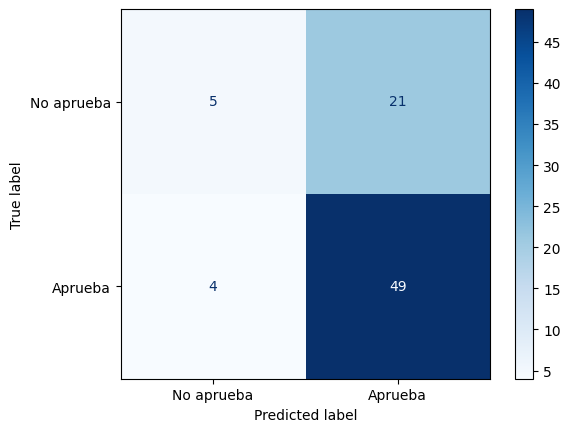

In [23]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

pred_log = (prob >= 0.5).astype(int)   # aprueba si la probabilidad es 0.5 o más

print("Exactitud:", round(accuracy_score(yl_test, pred_log), 3))
print("Precisión:", round(precision_score(yl_test, pred_log), 3))
print("Recall:", round(recall_score(yl_test, pred_log), 3))
print("Exactitud si siempre decimos que aprueba:", round(yl_test.mean(), 3))

ConfusionMatrixDisplay(confusion_matrix(yl_test, pred_log),
                       display_labels=["No aprueba", "Aprueba"]).plot(cmap="Blues")
plt.grid(False)
plt.show()

Se observa que el modelo acierta el 68.4% de los casos, apenas un poco más que el 67.1% que se obtiene diciendo que todos aprueban. La precisión es 0.70, es decir que de los que predice que aprueban el 70% sí aprueba. El recall es 0.925, por lo que reconoce a la mayoría de los que aprueban. Sin embargo, de los 26 que no aprueban solo identifica a 5, así que no sirve mucho para detectar estudiantes en riesgo con este umbral.